# Compare calculated and experimental NMR shifts

## import

In [1]:
import mdtraj as md
import pandas as pd
import matplotlib.pyplot as plt
import pynmrstar as star
import matplotlib as mpl
import numpy as np

import os
import shutil

from mlcolvar.utils.io import load_dataframe


In [2]:
# add SPARTA+ to the PATH

SPARTA_DIR = r"C:\Users\vacaa\Documents\SPARTA+"
SPARTA_BIN = r"C:\Users\vacaa\Documents\SPARTA+\bin"

os.environ["SPARTAP_DIR"] = SPARTA_DIR
os.environ["PATH"] = SPARTA_BIN + os.pathsep + os.environ["PATH"]

print("sparta+.bat:", shutil.which("sparta+.bat"))
print("sparta+:", shutil.which("sparta+"))

sparta+.bat: C:\Users\vacaa\Documents\SPARTA+\bin\sparta+.bat
sparta+: C:\Users\vacaa\Documents\SPARTA+\bin\sparta+.BAT


In [3]:
#plot-related stuff
import matplotlib.pyplot as plt
from IPython.display import clear_output

#set bigger font sizes
SMALL_SIZE = 8
MEDIUM_SIZE = 8
BIG_SIZE = 8
plt.rc('font', size=SMALL_SIZE)        # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)   # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)  # legend fontsize
plt.rc('figure', titlesize=BIG_SIZE)   # fontsize of the figure title

try:
# https://github.com/luigibonati/fessa-color-palette/blob/master/fessa.py
    import fessa
    plt.set_cmap('fessa')
except:
    pass # no big deal

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,

    # Axes
    "axes.titlesize": 8,
    "axes.labelsize": 8,

    # Tick labels
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    # Legend
    "legend.fontsize": 8,

    # Figure title
    "figure.titlesize": 8,

    # Colorbar (uses axes settings, but these help in some cases)
    "axes.titlepad": 6,
})

In [4]:
# add SPARTA+ to the PATH

SPARTA_DIR = r"C:\Users\vacaa\Documents\SPARTA+"
SPARTA_BIN = r"C:\Users\vacaa\Documents\SPARTA+\bin"

os.environ["SPARTAP_DIR"] = SPARTA_DIR
os.environ["PATH"] = SPARTA_BIN + os.pathsep + os.environ["PATH"]

print("sparta+.bat:", shutil.which("sparta+.bat"))
print("sparta+:", shutil.which("sparta+"))

sparta+.bat: C:\Users\vacaa\Documents\SPARTA+\bin\sparta+.bat
sparta+: C:\Users\vacaa\Documents\SPARTA+\bin\sparta+.BAT


In [5]:
#useful constants for our simulations
KB = 0.0083144621
T = 300
BETA = 1/(KB*T)
KBT = KB*T

cm2inch = 1/2.54

## Conventiona MD FCP1term

### Calculate SPARTA+ shifts and read NMR-STAR

In [ ]:
path_folding = r"C:/Users/vacaa/Documents/REPORTS/170/data/Folding"
STAR_FILE = r'C:/Users/vacaa/Documents/REPORTS/170/Code/FCP1_NMR.txt'
BLOCK_SIZE = 500
# =============================================================================
# Conventional MD
# =============================================================================

traj = md.load(
    f"{path_folding}/FCP1/plumed/chainB.xtc",
    top=f"{path_folding}/FCP1/plumed/chainB.pdb"
)
traj = traj[::20]
traj = traj.atom_slice(traj.topology.select("protein"))

# --- SPARTA+ prediction for every trajectory frame ---
blocks = []
for start in range(0, traj.n_frames, BLOCK_SIZE):
    print('Block number: ', round(start/BLOCK_SIZE))
    stop = min(start + BLOCK_SIZE, traj.n_frames)
    block = md.chemical_shifts_spartaplus(traj[start:stop])
    blocks.append(block)


shifts = pd.concat(blocks, axis=1)

# Average predicted chemical shift over all MD frames
pred = shifts.mean(axis=1).rename("calc").reset_index()
pred.columns = ["resSeq", "atom", "calc"]
pred['calc_std'] = shifts.std(axis=1).values

# --- Read experimental NMR-STAR ---
entry = star.Entry.from_file(STAR_FILE)

exp_tables = []
for loop in entry.get_loops_by_category("Atom_chem_shift"):
    x = loop.get_tag(["Comp_index_ID", "Comp_ID", "Atom_ID", "Val"])
    exp_tables.append(
        pd.DataFrame(x, columns=["resSeq", "resName", "atom", "exp"])
    )

exp = pd.concat(exp_tables, ignore_index=True)
exp["resSeq"] = pd.to_numeric(exp["resSeq"], errors="coerce")
exp.replace({'H':'HN'},  inplace=True)
exp["resSeq"] = exp["resSeq"] + 961 - max(exp["resSeq"])
exp["exp"] = pd.to_numeric(exp["exp"], errors="coerce")
exp = exp.dropna(subset=["resSeq", "exp"])
exp["resSeq"] = exp["resSeq"].astype(int)

# --- Match experimental and calculated shifts ---
data = exp.merge(
    pred[["resSeq", "atom", "calc", "calc_std"]],
    on=["resSeq", "atom"],
    how="inner"
)

data = data.dropna(subset=["calc"])
data.head()

Block number:  0


c:\Users\vacaa\Documents\REPORTS\170\Code\.venv\Lib\site-packages\mdtraj\nmr\shift_wrappers.py:346: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  results.name[results.name == "HN"] = "H"


Block number:  1


c:\Users\vacaa\Documents\REPORTS\170\Code\.venv\Lib\site-packages\mdtraj\nmr\shift_wrappers.py:346: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  results.name[results.name == "HN"] = "H"


Block number:  2


c:\Users\vacaa\Documents\REPORTS\170\Code\.venv\Lib\site-packages\mdtraj\nmr\shift_wrappers.py:346: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  results.name[results.name == "HN"] = "H"


... (33 outputs left out)

c:\Users\vacaa\Documents\REPORTS\170\Code\.venv\Lib\site-packages\mdtraj\nmr\shift_wrappers.py:346: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  results.name[results.name == "HN"] = "H"


Block number:  20


c:\Users\vacaa\Documents\REPORTS\170\Code\.venv\Lib\site-packages\mdtraj\nmr\shift_wrappers.py:346: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  results.name[results.name == "HN"] = "H"


,resSeq,resName,atom,exp,calc,calc_std
0,941,GLY,HA2,3.97,3.960000,0.000000e+00
1,941,GLY,HA3,3.97,3.960000,0.000000e+00
2,941,GLY,C,174.30,174.900000,2.842313e-14
3,941,GLY,CA,45.40,45.100000,7.105783e-15
4,942,SER,HA,4.49,4.569855,2.263314e-01


Save data frame

In [ ]:
shifts.to_csv('FCP1term_conv_SPARTA+.csv')

,resSeq,atom,calc,calc_std
0,941,C,174.900000,2.842313e-14
1,941,CA,45.100000,7.105783e-15
2,941,HA2,3.960000,0.000000e+00
3,941,HA3,3.960000,0.000000e+00
4,942,C,174.836524,8.900531e-01
...,...,...,...,...
118,961,CA,55.300000,7.105783e-15
119,961,CB,32.600000,7.105783e-15
120,961,HA,4.480140,4.482015e-03
121,961,HN,8.283458,6.558350e-02


Load data frame

In [6]:
STAR_FILE = r'C:/Users/vacaa/Documents/REPORTS/170/Code/FCP1_NMR.txt'

a = pd.read_csv(r'C:\Users\vacaa\Documents\REPORTS\170\Code\FCP1term_conv_SPARTA+.csv')   
pred = a.drop(labels = ['resSeq', 'name'], axis = 1).mean(axis=1).rename("calc").reset_index()
pred["resSeq"] = a["resSeq"]
pred["atom"] = a["name"]

pred['calc_std'] = a.drop(labels = ['resSeq', 'name'], axis = 1).std(axis=1).values

# --- Read experimental NMR-STAR ---
entry = star.Entry.from_file(STAR_FILE)

exp_tables = []
for loop in entry.get_loops_by_category("Atom_chem_shift"):
    x = loop.get_tag(["Comp_index_ID", "Comp_ID", "Atom_ID", "Val"])
    exp_tables.append(
        pd.DataFrame(x, columns=["resSeq", "resName", "atom", "exp"])
    )

exp = pd.concat(exp_tables, ignore_index=True)
exp["resSeq"] = pd.to_numeric(exp["resSeq"], errors="coerce")
exp.replace({'H':'HN'},  inplace=True)
exp["resSeq"] = exp["resSeq"] + 961 - max(exp["resSeq"])
exp["exp"] = pd.to_numeric(exp["exp"], errors="coerce")
exp = exp.dropna(subset=["resSeq", "exp"])
exp["resSeq"] = exp["resSeq"].astype(int)

# --- Match experimental and calculated shifts ---
data = exp.merge(
    pred[["resSeq", "atom", "calc", "calc_std"]],
    on=["resSeq", "atom"],
    how="inner"
)

data = data.dropna(subset=["calc"])
data.head()

,resSeq,resName,atom,exp,calc,calc_std
0,941,GLY,HA2,3.97,3.960000,0.000000e+00
1,941,GLY,HA3,3.97,3.960000,0.000000e+00
2,941,GLY,C,174.30,174.900000,2.842313e-14
3,941,GLY,CA,45.40,45.100000,7.105783e-15
4,942,SER,HN,8.16,8.413997,2.226168e-01


### Secondary shift Ca-Cb

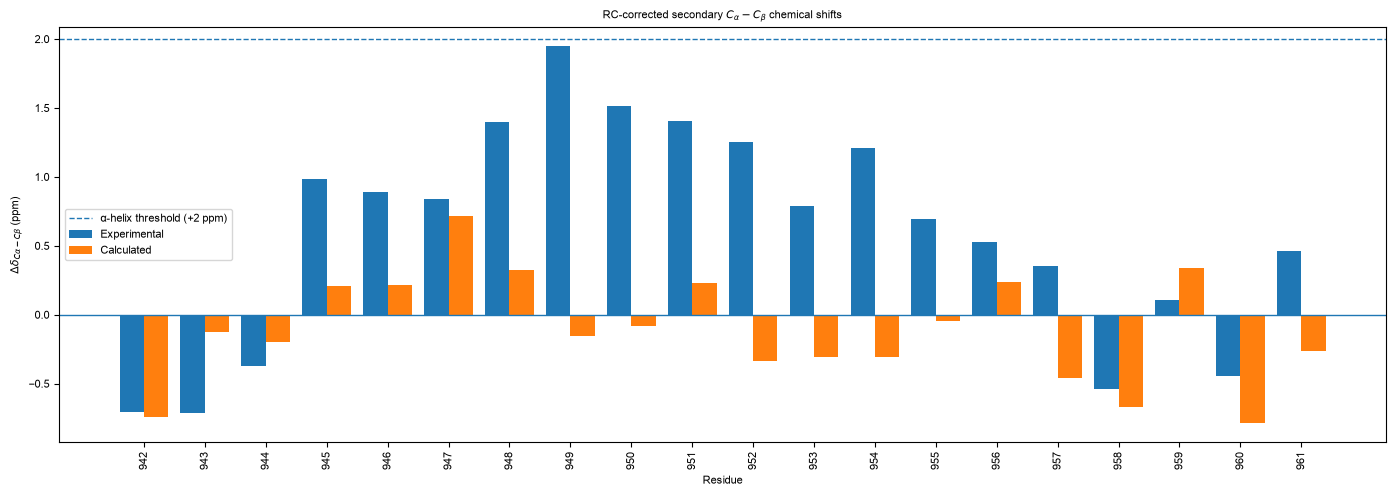

In [13]:
# =======================================================
# 1. Read random-coil reference
# =======================================================

RC_FILE = r"C:\Users\vacaa\Documents\REPORTS\170\Code\FCP1term_random_coil_NMR.txt"

rc = pd.read_csv(
    RC_FILE,
    sep=r"\s+",
    na_values="***"
)

# Match naming used in `data`
rc = rc.rename(columns={
    "Res": "resSeq",
    "CO": "C"
})

# =======================================================
# 2. Convert random-coil data to long format
# =======================================================

rc = rc.melt(
    id_vars="resSeq",
    value_vars=["CA", "CB", "C", "N", "HN", "HA"],
    var_name="atom",
    value_name="rc"
)

# =======================================================
# 3. Shift residue numbering
# =======================================================

rc["resSeq"] = rc["resSeq"] + 961 - rc["resSeq"].max()

rc["resSeq"] = pd.to_numeric(
    rc["resSeq"],
    errors="coerce"
)

rc["rc"] = pd.to_numeric(
    rc["rc"],
    errors="coerce"
)

# =======================================================
# 4. Merge random-coil values with experimental/calculated
# =======================================================

data_rc = data.merge(
    rc,
    on=["resSeq", "atom"],
    how="inner"
)

data_rc = data_rc.dropna(subset=["rc"]).copy()

# =======================================================
# 5. Calculate secondary chemical shifts
# =======================================================

# Experimental secondary shift
data_rc["exp_rc"] = data_rc["exp"] - data_rc["rc"]

# Calculated secondary shift
data_rc["calc_rc"] = data_rc["calc"] - data_rc["rc"]

# =======================================================
# 6. Keep only Cα and Cβ
# =======================================================

ca_cb = data_rc[
    data_rc["atom"].isin(["CA", "CB"])
].copy()

# =======================================================
# 7. Pivot CA and CB onto the same residue
# =======================================================

pivot = ca_cb.pivot_table(
    index=["resSeq", "resName"],
    columns="atom",
    values=["exp_rc", "calc_rc"],
    aggfunc="first"
)

# Flatten multi-index columns
pivot.columns = [
    f"{x}_{y}"
    for x, y in pivot.columns
]

pivot = pivot.reset_index()

# =======================================================
# 8. Calculate secondary Cα-Cβ shift
# =======================================================

# Experimental:
#
# Δδ(CA-CB) =
# (exp_CA - RC_CA) - (exp_CB - RC_CB)

pivot["exp_CA_CB"] = (
    pivot["exp_rc_CA"]
    - pivot["exp_rc_CB"]
)

# Calculated:
#
# Δδ(CA-CB) =
# (calc_CA - RC_CA) - (calc_CB - RC_CB)

pivot["calc_CA_CB"] = (
    pivot["calc_rc_CA"]
    - pivot["calc_rc_CB"]
)

# =======================================================
# 9. Remove residues with missing CA or CB
# =======================================================

plot_df = pivot.dropna(
    subset=["exp_CA_CB", "calc_CA_CB"]
).copy()

# Sort by residue number
plot_df = plot_df.sort_values("resSeq")

# =======================================================
# 10. Plot experimental and calculated secondary shifts
# =======================================================

fig, ax = plt.subplots(figsize=(14, 5))

x = np.arange(len(plot_df))
width = 0.4

ax.bar(
    x - width / 2,
    plot_df["exp_CA_CB"],
    width=width,
    label="Experimental"
)

ax.bar(
    x + width / 2,
    plot_df["calc_CA_CB"],
    width=width,
    label="Calculated"
)

# Zero reference
ax.axhline(
    0,
    linewidth=1
)

# α-helix threshold mentioned in the paper
ax.axhline(
    2.0,
    linestyle="--",
    linewidth=1,
    label="α-helix threshold (+2 ppm)"
)

# X axis
ax.set_xticks(x)
ax.set_xticklabels(
    plot_df["resSeq"].astype(int).astype(str),
    rotation=90
)

ax.set_xlabel("Residue")
ax.set_ylabel(
    r"$\Delta\delta_{C\alpha-C\beta}$ (ppm)"
)

ax.set_title(
    r"RC-corrected secondary $C_\alpha-C_\beta$ chemical shifts"
)

ax.legend()

plt.tight_layout()
plt.show()


In [18]:
KBT * np.log(2.2*1e-6) - KBT * np.log(1.0*1e-6) 

np.float64(1.9666796520644283)

### Comparison plot

Matched shifts: 123
RMSE: 0.853 ppm
MAE:  0.484 ppm
Pearson r: 1.000


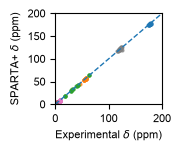

In [90]:
# Cell 3: compare experimental and calculated chemical shifts

fig, ax = plt.subplots(figsize=(3.5*cm2inch, 3*cm2inch))
# fig, ax = plt.subplots(figsize=(7*cm2inch, 6*cm2inch))

# Plot each atom type separately
for atom, g in data.groupby("atom"):
    ax.scatter(g["exp"], g["calc"], s=4, alpha=0.7, label=atom)

# Ideal agreement line
lo = min(data["exp"].min(), data["calc"].min())
hi = max(data["exp"].max(), data["calc"].max())
ax.plot([0, 200], [0, 200], "--", lw=1)

ax.set_xlabel(r"Experimental $\delta$ (ppm)")
ax.set_ylabel(r"SPARTA+ $\delta$ (ppm)")
# ax.legend(frameon=False, ncol=2)
ax.set_xlim(0,200)
ax.set_ylim(0,200)

# Simple statistics
print(f"Matched shifts: {len(data)}")
print(f"RMSE: {((data['calc'] - data['exp'])**2).mean()**0.5:.3f} ppm")
print(f"MAE:  {(data['calc'] - data['exp']).abs().mean():.3f} ppm")
print(f"Pearson r: {data['exp'].corr(data['calc']):.3f}")

plt.savefig('images/NMR/NMR_absolute_calc_exp_conventional_MD_v2.png', dpi = 600, bbox_inches="tight",)


Matched shifts: 120
RMSE: 0.652 ppm
MAE:  0.444 ppm
Pearson r: 0.196


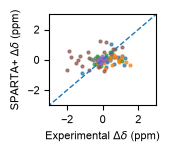

In [91]:
# Cell 3: compare random-coil-corrected chemical shifts

# --- Read random-coil reference ---
RC_FILE = r"C:\Users\vacaa\Documents\REPORTS\170\Code\FCP1term_random_coil_NMR.txt"

rc = pd.read_csv(
    RC_FILE,
    sep=r"\s+",
    na_values="**.***"
)

# Match naming used in `data`
rc = rc.rename(columns={
    "Res": "resSeq",
    "CO": "C"
})

# Convert to long format -- all available atoms
rc = rc.melt(
    id_vars="resSeq",
    value_vars=["CA", "CB", "C", "N", "HN", "HA"],
    var_name="atom",
    value_name="rc"
)

# Shift residue numbering
rc["resSeq"] = rc["resSeq"] + 961 - max(rc["resSeq"])

rc["resSeq"] = pd.to_numeric(rc["resSeq"], errors="coerce")
rc["rc"] = pd.to_numeric(rc["rc"], errors="coerce")

# --- Add random-coil values to experimental/calculated data ---
data_rc = data.merge(
    rc,
    on=["resSeq", "atom"],
    how="inner"
).dropna(subset=["rc"])[:-1]

# --- Random-coil-corrected shifts ---
data_rc["exp_rc"] = data_rc["exp"] - data_rc["rc"]
data_rc["calc_rc"] = data_rc["calc"] - data_rc["rc"]

# --- Plot ---
fig, ax = plt.subplots(figsize=(3.5*cm2inch, 3*cm2inch))
# fig, ax = plt.subplots(figsize=(7*cm2inch, 6*cm2inch))

for atom, g in data_rc.groupby("atom"):
    ax.scatter(
        g["exp_rc"],
        g["calc_rc"],
        s=4,
        alpha=0.7,
        label=atom
    )

# Ideal agreement line
lo = min(
    data_rc["exp_rc"].min(),
    data_rc["calc_rc"].min()
)

hi = max(
    data_rc["exp_rc"].max(),
    data_rc["calc_rc"].max()
)

ax.plot(
    [-5, 5],
    [-5, 5],
    "--",
    lw=1
)

ax.set_xlabel(r"Experimental $\Delta\delta$ (ppm)")
ax.set_ylabel(r"SPARTA+ $\Delta\delta$ (ppm)")

# ax.legend(frameon=False, loc = 'upper left', ncol=2)
ax.set_xlim(-3,3)
ax.set_ylim(-3,3)

# --- Statistics ---
error = data_rc["calc_rc"] - data_rc["exp_rc"]

print(f"Matched shifts: {len(data_rc)}")
print(f"RMSE: {((error**2).mean())**0.5:.3f} ppm")
print(f"MAE:  {error.abs().mean():.3f} ppm")
print(
    f"Pearson r: "
    f"{data_rc['exp_rc'].corr(data_rc['calc_rc']):.3f}"
)

plt.savefig('images/NMR/NMR_no_rc_calc_exp_conventional_MD_v2.png', dpi = 600, bbox_inches="tight",)

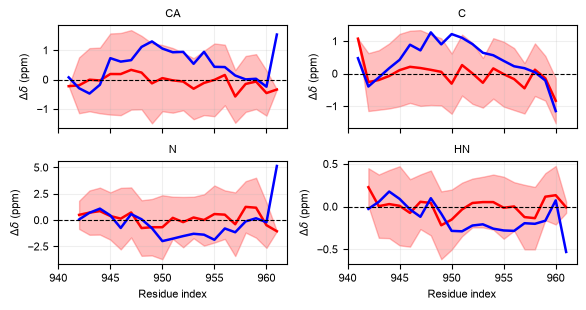

In [92]:
# =============================================================================
# Cell 3 — Random-coil corrected chemical shifts
# =============================================================================

import matplotlib.pyplot as plt

RC_FILE = r"C:\Users\vacaa\Documents\REPORTS\170\Code\FCP1term_random_coil_NMR.txt"

# --- Read random-coil shifts ---
rc = pd.read_csv(
    RC_FILE,
    sep=r"\s+",
    na_values="**.***"
)

rc = rc.rename(columns={"Res": "resSeq", "CO": "C"})
rc["resSeq"] = rc["resSeq"] + 961 - max(rc["resSeq"])


# Convert to numeric
for col in ["resSeq", "CA", "C", "N", "HN", "HA"]:
    rc[col] = pd.to_numeric(rc[col], errors="coerce")

rc["resSeq"] = rc["resSeq"].astype(int)

# --- Convert random-coil table from wide to long format ---
rc_long = rc.melt(
    id_vars="resSeq",
    value_vars=["CA", "C", "N", "HN"],
    var_name="atom",
    value_name="random_coil"
).dropna(subset=["random_coil"])

# --- Add random-coil values to experimental/calculated data ---
data_rc = data.merge(
    rc_long,
    on=["resSeq", "atom"],
    how="inner"
)

# --- Secondary chemical shifts ---
data_rc["exp_sec"] = (
    data_rc["exp"] - data_rc["random_coil"]
)

data_rc["calc_sec"] = (
    data_rc["calc"] - data_rc["random_coil"]
)

# --- Plot ---
atoms = ["CA", "C", "N", "HN"]

fig, axes = plt.subplots(
    2, 2,
    figsize=(15*cm2inch, 8*cm2inch),
    sharex=True
)

for ax, atom in zip(axes.flat, atoms):

    d = data_rc[
        data_rc["atom"] == atom
    ].sort_values("resSeq")

    ax.plot(
        d["resSeq"],
        d["calc_sec"],
        color="red",
        lw=1.8,
        label="MD / SPARTA+"
    )
    ax.fill_between(d["resSeq"],
                    d["calc_sec"] - d['calc_std'],
                    d["calc_sec"] + d['calc_std'],
                    color="red", 
                    alpha = 0.25)

    ax.plot(
        d["resSeq"],
        d["exp_sec"],
        color="blue",
        lw=1.8,
        label="Experiment"
    )

    ax.axhline(
        0,
        color="black",
        lw=0.8,
        ls="--"
    )

    ax.set_title(atom)
    ax.set_ylabel(r"$\Delta\delta$ (ppm)")
    ax.grid(alpha=0.2)

axes[1, 0].set_xlabel("Residue index")
axes[1, 1].set_xlabel("Residue index")

plt.tight_layout()
plt.savefig('images/NMR/NMR_no_rc_index_conventional_MD_v1.png', dpi = 600, bbox_inches="tight",)
plt.show()

## OneOPES symulations

### Calculate SPARTA+ shifts and read NMR-STAR

In [85]:
path_folding = r"C:/Users/vacaa/Documents/REPORTS/170/data/Folding"
STAR_FILE = r'C:/Users/vacaa/Documents/REPORTS/170/Code/FCP1_NMR.txt'
repeat = 4

# =============================================================================
# Conventional MD
# =============================================================================

traj = md.load(
        f"{path_folding}/One_OPES_{repeat}/0/md_0_2.xtc",
        top=f"{path_folding}/One_OPES_{repeat}/0/fcp1.pdb"
    )
traj = traj[::10]
traj = traj.atom_slice(traj.topology.select("protein"))
# --- SPARTA+ prediction for every trajectory frame ---
shifts = md.chemical_shifts_spartaplus(traj)

# --- Read weights from the COLVAR ---
colvar = load_dataframe(f'{path_folding}/One_OPES_{repeat}/0/COLVAR.0')
bias = colvar['opes1.bias'].to_numpy()[::500]
logweights = BETA * (bias - np.max(bias))
weights = np.exp(logweights)
weights /= np.sum(weights)

# Average predicted chemical shift over all MD frames
X = shifts.to_numpy(dtype=float)
weighted_mean = np.sum(
    X * weights[None, :],
    axis=1
)
weighted_std = np.sqrt(
    np.sum(
        weights[None, :] *
        (X - weighted_mean[:, None])**2,
        axis=1
    )
)

pred = shifts.index.to_frame(index=False)
pred.columns = ["resSeq", "atom"]
pred["calc"] = weighted_mean
pred["calc_std"] = weighted_std

# --- Read experimental NMR-STAR ---
entry = star.Entry.from_file(STAR_FILE)

exp_tables = []
for loop in entry.get_loops_by_category("Atom_chem_shift"):
    x = loop.get_tag(["Comp_index_ID", "Comp_ID", "Atom_ID", "Val"])
    exp_tables.append(
        pd.DataFrame(x, columns=["resSeq", "resName", "atom", "exp"])
    )

exp = pd.concat(exp_tables, ignore_index=True)
exp["resSeq"] = pd.to_numeric(exp["resSeq"], errors="coerce")
exp.replace({'H':'HN'},  inplace=True)
exp["resSeq"] = exp["resSeq"] + 961 - max(exp["resSeq"])
exp["exp"] = pd.to_numeric(exp["exp"], errors="coerce")
exp = exp.dropna(subset=["resSeq", "exp"])
exp["resSeq"] = exp["resSeq"].astype(int)

# --- Match experimental and calculated shifts ---
data = exp.merge(
    pred[["resSeq", "atom", "calc", "calc_std"]],
    on=["resSeq", "atom"],
    how="inner"
)

data = data.dropna(subset=["calc"])
data.head()

c:\Users\vacaa\Documents\REPORTS\170\Code\.venv\Lib\site-packages\mdtraj\nmr\shift_wrappers.py:346: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  results.name[results.name == "HN"] = "H"


,resSeq,resName,atom,exp,calc,calc_std
0,941,GLY,HA2,3.97,3.960000,0.000000e+00
1,941,GLY,HA3,3.97,3.960000,0.000000e+00
2,941,GLY,C,174.30,174.900000,2.842171e-14
3,941,GLY,CA,45.40,45.100000,7.105427e-15
4,942,SER,HN,8.16,8.492886,4.676419e-01


### Plots

Matched shifts: 123
RMSE: 0.894 ppm
MAE:  0.534 ppm
Pearson r: 1.000


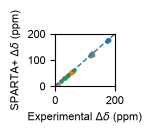

In [86]:
# Cell 3: compare experimental and calculated chemical shifts

fig, ax = plt.subplots(figsize=(3.5*cm2inch, 3*cm2inch))

# Plot each atom type separately
for atom, g in data.groupby("atom"):
    ax.scatter(g["exp"], g["calc"], s=4, alpha=0.7, label=atom)

# Ideal agreement line
lo = min(data["exp"].min(), data["calc"].min())
hi = max(data["exp"].max(), data["calc"].max())
ax.plot([0, 200], [0, 200], "--", lw=1)
ax.set_xlim(0,200)
ax.set_ylim(0,200)

ax.set_xlabel(r"Experimental $\Delta\delta$ (ppm)")
ax.set_ylabel(r"SPARTA+ $\Delta\delta$ (ppm)")
# ax.legend(frameon=False, ncol=2)

plt.tight_layout()

# Simple statistics
print(f"Matched shifts: {len(data)}")
print(f"RMSE: {((data['calc'] - data['exp'])**2).mean()**0.5:.3f} ppm")
print(f"MAE:  {(data['calc'] - data['exp']).abs().mean():.3f} ppm")
print(f"Pearson r: {data['exp'].corr(data['calc']):.3f}")

plt.savefig(f'images/NMR/NMR_absolute_calc_exp_OneOPES_{repeat}.png', dpi = 600, bbox_inches="tight",)


Matched shifts: 120
RMSE: 0.706 ppm
MAE:  0.496 ppm
Pearson r: 0.033


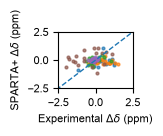

In [87]:
# Cell 3: compare random-coil-corrected chemical shifts

# --- Read random-coil reference ---
RC_FILE = r"C:\Users\vacaa\Documents\REPORTS\170\Code\FCP1term_random_coil_NMR.txt"

rc = pd.read_csv(
    RC_FILE,
    sep=r"\s+",
    na_values="**.***"
)

# Match naming used in `data`
rc = rc.rename(columns={
    "Res": "resSeq",
    "CO": "C"
})

# Convert to long format -- all available atoms
rc = rc.melt(
    id_vars="resSeq",
    value_vars=["CA", "CB", "C", "N", "HN", "HA"],
    var_name="atom",
    value_name="rc"
)

# Shift residue numbering
rc["resSeq"] = rc["resSeq"] + 961 - max(rc["resSeq"])

rc["resSeq"] = pd.to_numeric(rc["resSeq"], errors="coerce")
rc["rc"] = pd.to_numeric(rc["rc"], errors="coerce")

# --- Add random-coil values to experimental/calculated data ---
data_rc = data.merge(
    rc,
    on=["resSeq", "atom"],
    how="inner"
).dropna(subset=["rc"])[:-1]


# --- Random-coil-corrected shifts ---
data_rc["exp_rc"] = data_rc["exp"] - data_rc["rc"]
data_rc["calc_rc"] = data_rc["calc"] - data_rc["rc"]

# --- Plot ---
fig, ax = plt.subplots(figsize=(3.5*cm2inch, 3*cm2inch))

for atom, g in data_rc.groupby("atom"):
    ax.scatter(
        g["exp_rc"],
        g["calc_rc"],
        s=4,
        alpha=0.7,
        label=atom
    )

ax.plot(
    [-5, 5],
    [-5, 5],
    "--",
    lw=1
)

ax.set_xlabel(r"Experimental $\Delta\delta$ (ppm)")
ax.set_ylabel(r"SPARTA+ $\Delta\delta$ (ppm)")

# ax.legend(frameon=False, loc = "upper left", ncol=2)
ax.set_xlim(-2.5,2.5)
ax.set_ylim(-2.5,2.5)

plt.tight_layout()

# --- Statistics ---
error = data_rc["calc_rc"] - data_rc["exp_rc"]

print(f"Matched shifts: {len(data_rc)}")
print(f"RMSE: {((error**2).mean())**0.5:.3f} ppm")
print(f"MAE:  {error.abs().mean():.3f} ppm")
print(
    f"Pearson r: "
    f"{data_rc['exp_rc'].corr(data_rc['calc_rc']):.3f}"
)
plt.savefig(f'images/NMR/NMR_no_rc_calc_exp_OneOPES_{repeat}.png', dpi = 600, bbox_inches="tight",)

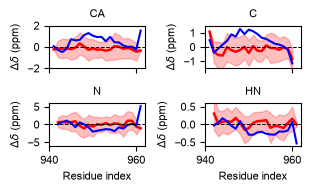

In [88]:
# =============================================================================
# Cell 3 — Random-coil corrected chemical shifts
# =============================================================================

RC_FILE = r"C:\Users\vacaa\Documents\REPORTS\170\Code\FCP1term_random_coil_NMR.txt"

# --- Read random-coil shifts ---
rc = pd.read_csv(
    RC_FILE,
    sep=r"\s+",
    na_values="**.***"
)

rc = rc.rename(columns={"Res": "resSeq", "CO": "C"})
rc["resSeq"] = rc["resSeq"] + 961 - max(rc["resSeq"])


# Convert to numeric
for col in ["resSeq", "CA", "C", "N", "HN", "HA"]:
    rc[col] = pd.to_numeric(rc[col], errors="coerce")

rc["resSeq"] = rc["resSeq"].astype(int)

# --- Convert random-coil table from wide to long format ---
rc_long = rc.melt(
    id_vars="resSeq",
    value_vars=["CA", "C", "N", "HN"],
    var_name="atom",
    value_name="random_coil"
).dropna(subset=["random_coil"])

# --- Add random-coil values to experimental/calculated data ---
data_rc = data.merge(
    rc_long,
    on=["resSeq", "atom"],
    how="inner"
)

# --- Secondary chemical shifts ---
data_rc["exp_sec"] = (
    data_rc["exp"] - data_rc["random_coil"]
)

data_rc["calc_sec"] = (
    data_rc["calc"] - data_rc["random_coil"]
)

# --- Plot ---
atoms = ["CA", "C", "N", "HN"]

fig, axes = plt.subplots(
    2, 2,
    figsize=(8*cm2inch, 5*cm2inch),
    sharex=True
)

for ax, atom in zip(axes.flat, atoms):

    d = data_rc[
        data_rc["atom"] == atom
    ].sort_values("resSeq")

    ax.plot(
        d["resSeq"],
        d["calc_sec"],
        color="red",
        lw=1.8,
        label="MD / SPARTA+"
    )
    ax.fill_between(d["resSeq"],
                    d["calc_sec"] - d['calc_std'],
                    d["calc_sec"] + d['calc_std'],
                    color="red", 
                    alpha = 0.25)

    ax.plot(
        d["resSeq"],
        d["exp_sec"],
        color="blue",
        lw=1.5,
        label="Experiment"
    )

    ax.axhline(
        0,
        color="black",
        lw=0.7,
        ls="--"
    )

    ax.set_title(atom)
    ax.set_ylabel(r"$\Delta\delta$ (ppm)")
    # ax.grid(alpha=0.2)

axes[1, 0].set_xlabel("Residue index")
axes[1, 1].set_xlabel("Residue index")
axes[0, 0].set_ylim(-2,2)
axes[0, 1].set_ylim(-1.5,1.5)
axes[1, 0].set_ylim(-6,6)
axes[1, 1].set_ylim(-0.6,0.6)



plt.tight_layout()
plt.savefig(f'images/NMR/NMR_no_rc_index_OneOPES_{repeat}.png', dpi = 600, bbox_inches="tight",)
plt.show()

### NO Weight

In [70]:
path_folding = r"C:/Users/vacaa/Documents/REPORTS/170/data/Folding"
STAR_FILE = r'C:/Users/vacaa/Documents/REPORTS/170/Code/FCP1_NMR.txt'
repeat = 3

# =============================================================================
# Conventional MD
# =============================================================================

traj = md.load(
        f"{path_folding}/One_OPES_{repeat}/0/md_0_2.xtc",
        top=f"{path_folding}/One_OPES_{repeat}/0/fcp1.pdb"
    )
traj = traj[::10]
traj = traj.atom_slice(traj.topology.select("protein"))
# --- SPARTA+ prediction for every trajectory frame ---
shifts = md.chemical_shifts_spartaplus(traj)

# --- Read weights from the COLVAR ---
colvar = load_dataframe(f'{path_folding}/One_OPES_{repeat}/0/COLVAR.0')
colvar['opes1.bias'] = 0
bias = colvar['opes1.bias'].to_numpy()[::500]
logweights = BETA * (bias - np.max(bias))
weights = np.exp(logweights)
weights /= np.sum(weights)

# Average predicted chemical shift over all MD frames
X = shifts.to_numpy(dtype=float)
weighted_mean = np.sum(
    X * weights[None, :],
    axis=1
)
weighted_std = np.sqrt(
    np.sum(
        weights[None, :] *
        (X - weighted_mean[:, None])**2,
        axis=1
    )
)

pred = shifts.index.to_frame(index=False)
pred.columns = ["resSeq", "atom"]
pred["calc"] = weighted_mean
pred["calc_std"] = weighted_std

# --- Read experimental NMR-STAR ---
entry = star.Entry.from_file(STAR_FILE)

exp_tables = []
for loop in entry.get_loops_by_category("Atom_chem_shift"):
    x = loop.get_tag(["Comp_index_ID", "Comp_ID", "Atom_ID", "Val"])
    exp_tables.append(
        pd.DataFrame(x, columns=["resSeq", "resName", "atom", "exp"])
    )

exp = pd.concat(exp_tables, ignore_index=True)
exp["resSeq"] = pd.to_numeric(exp["resSeq"], errors="coerce")
exp.replace({'H':'HN'},  inplace=True)
exp["resSeq"] = exp["resSeq"] + 961 - max(exp["resSeq"])
exp["exp"] = pd.to_numeric(exp["exp"], errors="coerce")
exp = exp.dropna(subset=["resSeq", "exp"])
exp["resSeq"] = exp["resSeq"].astype(int)

# --- Match experimental and calculated shifts ---
data = exp.merge(
    pred[["resSeq", "atom", "calc", "calc_std"]],
    on=["resSeq", "atom"],
    how="inner"
)

data = data.dropna(subset=["calc"])
data.head()

c:\Users\vacaa\Documents\REPORTS\170\Code\.venv\Lib\site-packages\mdtraj\nmr\shift_wrappers.py:346: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  results.name[results.name == "HN"] = "H"


,resSeq,resName,atom,exp,calc,calc_std
0,941,GLY,HA2,3.97,3.960000,1.776357e-15
1,941,GLY,HA3,3.97,3.960000,1.776357e-15
2,941,GLY,C,174.30,174.900000,0.000000e+00
3,941,GLY,CA,45.40,45.100000,7.105427e-15
4,942,SER,HN,8.16,8.443846,2.338203e-01


Matched shifts: 120
RMSE: 0.443 ppm
MAE:  0.293 ppm
Pearson r: 0.738


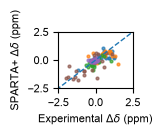

In [71]:
# Cell 3: compare random-coil-corrected chemical shifts

# --- Read random-coil reference ---
RC_FILE = r"C:\Users\vacaa\Documents\REPORTS\170\Code\FCP1term_random_coil_NMR.txt"

rc = pd.read_csv(
    RC_FILE,
    sep=r"\s+",
    na_values="**.***"
)

# Match naming used in `data`
rc = rc.rename(columns={
    "Res": "resSeq",
    "CO": "C"
})

# Convert to long format -- all available atoms
rc = rc.melt(
    id_vars="resSeq",
    value_vars=["CA", "CB", "C", "N", "HN", "HA"],
    var_name="atom",
    value_name="rc"
)

# Shift residue numbering
rc["resSeq"] = rc["resSeq"] + 961 - max(rc["resSeq"])

rc["resSeq"] = pd.to_numeric(rc["resSeq"], errors="coerce")
rc["rc"] = pd.to_numeric(rc["rc"], errors="coerce")

# --- Add random-coil values to experimental/calculated data ---
data_rc = data.merge(
    rc,
    on=["resSeq", "atom"],
    how="inner"
).dropna(subset=["rc"])[:-1]


# --- Random-coil-corrected shifts ---
data_rc["exp_rc"] = data_rc["exp"] - data_rc["rc"]
data_rc["calc_rc"] = data_rc["calc"] - data_rc["rc"]

# --- Plot ---
fig, ax = plt.subplots(figsize=(3.5*cm2inch, 3*cm2inch))

for atom, g in data_rc.groupby("atom"):
    ax.scatter(
        g["exp_rc"],
        g["calc_rc"],
        s=4,
        alpha=0.7,
        label=atom
    )

ax.plot(
    [-5, 5],
    [-5, 5],
    "--",
    lw=1
)

ax.set_xlabel(r"Experimental $\Delta\delta$ (ppm)")
ax.set_ylabel(r"SPARTA+ $\Delta\delta$ (ppm)")

# ax.legend(frameon=False, loc = "upper left", ncol=2)
ax.set_xlim(-2.5,2.5)
ax.set_ylim(-2.5,2.5)

plt.tight_layout()

# --- Statistics ---
error = data_rc["calc_rc"] - data_rc["exp_rc"]

print(f"Matched shifts: {len(data_rc)}")
print(f"RMSE: {((error**2).mean())**0.5:.3f} ppm")
print(f"MAE:  {error.abs().mean():.3f} ppm")
print(
    f"Pearson r: "
    f"{data_rc['exp_rc'].corr(data_rc['calc_rc']):.3f}"
)
plt.savefig(f'images/NMR/NMR_no_rc_calc_exp_OneOPES_no_weight_{repeat}.png', dpi = 600, bbox_inches="tight",)

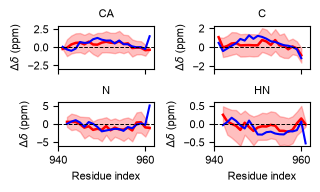

In [72]:
# =============================================================================
# Cell 3 — Random-coil corrected chemical shifts NO WEIGHT
# =============================================================================

RC_FILE = r"C:\Users\vacaa\Documents\REPORTS\170\Code\FCP1term_random_coil_NMR.txt"

# --- Read random-coil shifts ---
rc = pd.read_csv(
    RC_FILE,
    sep=r"\s+",
    na_values="**.***"
)

rc = rc.rename(columns={"Res": "resSeq", "CO": "C"})
rc["resSeq"] = rc["resSeq"] + 961 - max(rc["resSeq"])


# Convert to numeric
for col in ["resSeq", "CA", "C", "N", "HN", "HA"]:
    rc[col] = pd.to_numeric(rc[col], errors="coerce")

rc["resSeq"] = rc["resSeq"].astype(int)

# --- Convert random-coil table from wide to long format ---
rc_long = rc.melt(
    id_vars="resSeq",
    value_vars=["CA", "C", "N", "HN"],
    var_name="atom",
    value_name="random_coil"
).dropna(subset=["random_coil"])

# --- Add random-coil values to experimental/calculated data ---
data_rc = data.merge(
    rc_long,
    on=["resSeq", "atom"],
    how="inner"
)

# --- Secondary chemical shifts ---
data_rc["exp_sec"] = (
    data_rc["exp"] - data_rc["random_coil"]
)

data_rc["calc_sec"] = (
    data_rc["calc"] - data_rc["random_coil"]
)

# --- Plot ---
atoms = ["CA", "C", "N", "HN"]

fig, axes = plt.subplots(
    2, 2,
    figsize=(8*cm2inch, 5*cm2inch),
    sharex=True
)

for ax, atom in zip(axes.flat, atoms):

    d = data_rc[
        data_rc["atom"] == atom
    ].sort_values("resSeq")

    ax.plot(
        d["resSeq"],
        d["calc_sec"],
        color="red",
        lw=1.8,
        label="MD / SPARTA+"
    )
    ax.fill_between(d["resSeq"],
                    d["calc_sec"] - d['calc_std'],
                    d["calc_sec"] + d['calc_std'],
                    color="red", 
                    alpha = 0.25)

    ax.plot(
        d["resSeq"],
        d["exp_sec"],
        color="blue",
        lw=1.5,
        label="Experiment"
    )

    ax.axhline(
        0,
        color="black",
        lw=0.7,
        ls="--"
    )

    ax.set_title(atom)
    ax.set_ylabel(r"$\Delta\delta$ (ppm)")
    # ax.grid(alpha=0.2)

axes[1, 0].set_xlabel("Residue index")
axes[1, 1].set_xlabel("Residue index")
axes[0, 0].set_ylim(-3,3)
axes[0, 1].set_ylim(-2.3,2.3)
axes[1, 0].set_ylim(-6,6)
axes[1, 1].set_ylim(-0.6,0.6)



plt.tight_layout()
plt.savefig(f'images/NMR/NMR_no_rc_index_OneOPES_no_weight_{repeat}.png', dpi = 600, bbox_inches="tight",)
plt.show()